# Paper figures and tables

Figures, LaTeX tables and the numbers quoted in the experiment section, for every model with results and codes in `outputs/<model>/`; the example figure uses frames of the clips in `data-private/`. Output: `files/latex-paper/experiment/`.

In [1]:
import sys, tomllib
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binomtest, mannwhitneyu
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
OUT = ROOT / "files/latex-paper/experiment"
OUT.mkdir(parents=True, exist_ok=True)
CFG = tomllib.loads((ROOT / "configs/full_run.toml").read_text())
ALL_MODELS = tomllib.loads((ROOT / "configs/models.toml").read_text())
MODELS = {name: m for name, m in ALL_MODELS.items() if (ROOT / "outputs" / name / "agreement.csv").exists()}
CONDITIONS = ["Q_noE", "Q", "T", "T_told", "VT", "VTmis"]
WITH_E = CONDITIONS[1:]
CODES = ["cites_dialogue", "cites_visual", "says_insufficient", "names_missing_visual", "notices_mismatch"]
ABCD = ["prob_A", "prob_B", "prob_C", "prob_D"]

keys = pd.read_parquet(ROOT / "data-private/processed/answer_keys.parquet")[["question_id", "correct_answer_key"]]


def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * (p * (1 - p) / n + z**2 / (4 * n**2)) ** 0.5 / (1 + z**2 / n)
    return centre - half, centre + half


def load(name):
    df = pd.read_json(ROOT / "outputs" / name / "results.jsonl", lines=True).merge(keys, on="question_id")
    df["abstain"] = df.answer == "E"
    df["p_E"] = df.prob_E.fillna(0)
    df["best_wrong"] = df[ABCD].idxmax(axis=1).str[-1] != df.correct_answer_key
    df["claims_video"] = df.evidence_answer.isin(["video", "both"])
    labels = pd.read_json(ROOT / "outputs" / name / "judge_labels.jsonl", lines=True, dtype={"prompt_sha": str})
    df["key"] = df.question_id + "|" + df.condition
    return df.merge(labels.groupby("key")[CODES].all(), left_on="key", right_index=True, how="left")


data = {m["label"]: load(name) for name, m in MODELS.items()}
agreement = {m["label"]: pd.read_csv(ROOT / "outputs" / name / "agreement.csv", index_col=0) for name, m in MODELS.items()}
print(list(data), {k: len(v) for k, v in data.items()})

['Qwen-Omni', 'InternVL', 'Qwen-VL', 'LLaVA-Video', 'Gemma'] {'Qwen-Omni': 3588, 'InternVL': 3588, 'Qwen-VL': 3588, 'LLaVA-Video': 3588, 'Gemma': 3588}


## Numbers quoted in the text

In [2]:
rate = lambda df, cond, col: df.loc[df.condition == cond, col].mean() * 100
rows = []
for name, df in data.items():
    a = df.pivot(index="question_id", columns="condition", values="abstain")
    pE = df.pivot(index="question_id", columns="condition", values="p_E")
    answers = df.pivot(index="question_id", columns="condition", values="answer")
    mattered = answers["VT"] != answers["T"]
    rise = pE["T_told"] - pE["T"]
    row = {"model": name}
    for x, y in [("Q", "T"), ("T", "VT"), ("VT", "VTmis"), ("T", "T_told")]:
        start, stop = int((~a[x] & a[y]).sum()), int((a[x] & ~a[y]).sum())
        row[f"{x}>{y} start/stop"] = f"{start}/{stop} p={binomtest(start, start + stop).pvalue:.1g}"
    row["T_told rise mattered/not"] = f"{rise[mattered].mean():+.3f}/{rise[~mattered].mean():+.3f} p={mannwhitneyu(rise[mattered], rise[~mattered]).pvalue:.2g}"
    for c in ["T", "VT", "VTmis"]:
        d = df[df.condition == c]
        row[f"AUROC {c}"] = round(roc_auc_score(d.best_wrong, d.p_E), 2)
    row["kappa"] = f"{agreement[name].kappa.min():.2f}-{agreement[name].kappa.max():.2f}"
    row["T_told mentions video %"] = round(df[df.condition == "T_told"].explanation.str.contains(r"\bvideo", case=False).mean() * 100, 1)
    rows.append(row)
pd.set_option("display.max_colwidth", None)
pd.DataFrame(rows).set_index("model").T

model,Qwen-Omni,InternVL,Qwen-VL,LLaVA-Video,Gemma
Q>T start/stop,39/124 p=2e-11,64/164 p=3e-11,7/100 p=3e-22,14/102 p=1e-17,13/100 p=8e-18
T>VT start/stop,19/127 p=8e-21,14/183 p=1e-38,2/291 p=5e-84,31/25 p=0.5,2/276 p=2e-79
VT>VTmis start/stop,101/28 p=7e-11,47/35 p=0.2,211/15 p=2e-45,74/14 p=5e-11,193/18 p=3e-38
T>T_told start/stop,87/1 p=6e-25,72/1 p=2e-20,31/2 p=1e-07,11/9 p=0.8,35/7 p=2e-05
T_told rise mattered/not,+0.137/+0.111 p=0.00018,+0.100/+0.073 p=3.9e-06,+0.056/+0.042 p=0.0021,+0.011/+0.007 p=0.14,+0.013/+0.086 p=0.86
AUROC T,0.58,0.59,0.6,0.55,0.68
AUROC VT,0.57,0.56,0.55,0.53,0.63
AUROC VTmis,0.54,0.54,0.55,0.53,0.65
kappa,-0.00-0.98,0.73-1.00,0.47-0.99,0.67-0.98,0.72-0.99
T_told mentions video %,7.5,2.7,0.7,6.5,15.4


## Tables

In [3]:
def latex_table(path, header, rows, align):
    lines = [f"\\begin{{tabular}}{{{align}}}", "\\hline", header + " \\\\", "\\hline"]
    lines += [" & ".join(r) + " \\\\" for r in rows] + ["\\hline", "\\end{tabular}"]
    (OUT / path).write_text("\n".join(lines) + "\n")
    print((OUT / path).read_text())


pct = lambda v: f"{v:.0f}"
rows = []
for name, df in data.items():
    ab = [pct(rate(df, c, "abstain")) for c in WITH_E]
    best = [pct(100 - rate(df, c, "best_wrong")) for c in ["T", "VT", "VTmis"]]
    d = df[df.condition == "T"]
    rows.append([name] + ab + best + [f"{roc_auc_score(d.best_wrong, d.p_E):.2f}"])
latex_table("table_behavior.tex",
            "& \\multicolumn{5}{c|}{\\textbf{Abstained (\\%)}} & \\multicolumn{3}{c|}{\\textbf{Best A--D right (\\%)}} & \\textbf{AUROC} \\\\\n"
            "\\textbf{Model} & Q & T & T\\_told & VT & VTmis & T & VT & VTmis & T",
            rows, "|l|ccccc|ccc|c|")

rows = []
for name, m in MODELS.items():
    df = data[m["label"]]
    tokens = (df[df.condition == "VT"].set_index("question_id").n_input_tokens - df[df.condition == "T"].set_index("question_id").n_input_tokens).median()
    rows.append([m["label"], m["model_id"].split("/")[1].replace("_", "\\_"), m["llm"], m["size"], f"{tokens / 1000:.1f}k"])
latex_table("table_models.tex", "\\textbf{Model} & \\textbf{Checkpoint} & \\textbf{LLM} & \\textbf{Size} & \\textbf{Video tokens}", rows, "|l|l|l|c|c|")

rows = []
for name, df in data.items():
    rows.append([name] + [pct(rate(df, c, "claims_video")) for c in ["Q_noE", "VT", "VTmis"]]
                + [pct(rate(df, c, "cites_visual")) for c in ["Q_noE", "VT", "VTmis"]]
                + [f"{rate(df, 'VTmis', 'notices_mismatch'):.1f}", pct(rate(df, "T_told", "names_missing_visual"))])
latex_table("table_self_report.tex",
            "& \\multicolumn{3}{c|}{\\textbf{Says it used a video (\\%)}} & \\multicolumn{3}{c|}{\\textbf{Cites things seen (\\%)}} & \\textbf{Notices} & \\textbf{Names} \\\\\n"
            "\\textbf{Model} & Q\\_noE & VT & VTmis & Q\\_noE & VT & VTmis & \\textbf{mismatch} & \\textbf{missing video} \\\\\n"
            "& & & & & & & VTmis & T\\_told",
            rows, "|l|ccc|ccc|c|c|")

\begin{tabular}{|l|ccccc|ccc|c|}
\hline
& \multicolumn{5}{c|}{\textbf{Abstained (\%)}} & \multicolumn{3}{c|}{\textbf{Best A--D right (\%)}} & \textbf{AUROC} \\
\textbf{Model} & Q & T & T\_told & VT & VTmis & T & VT & VTmis & T \\
\hline
Qwen-Omni & 62 & 47 & 62 & 29 & 42 & 55 & 56 & 53 & 0.58 \\
InternVL & 59 & 42 & 54 & 14 & 16 & 51 & 56 & 49 & 0.59 \\
Qwen-VL & 97 & 82 & 87 & 33 & 66 & 50 & 60 & 51 & 0.60 \\
LLaVA-Video & 28 & 14 & 14 & 15 & 25 & 54 & 54 & 49 & 0.55 \\
Gemma & 96 & 81 & 86 & 35 & 65 & 52 & 57 & 51 & 0.68 \\
\hline
\end{tabular}

\begin{tabular}{|l|l|l|c|c|}
\hline
\textbf{Model} & \textbf{Checkpoint} & \textbf{LLM} & \textbf{Size} & \textbf{Video tokens} \\
\hline
Qwen-Omni & Qwen2.5-Omni-7B & Qwen2.5 & 7B & 9.6k \\
InternVL & InternVL2\_5-8B-MPO-hf & InternLM2.5 & 8B & 16.8k \\
Qwen-VL & Qwen2.5-VL-7B-Instruct & Qwen2.5 & 7B & 9.6k \\
LLaVA-Video & LLaVA-Video-7B-Qwen2-hf & Qwen2 & 7B & 12.5k \\
Gemma & gemma-4-12B-it & Gemma 4 & 12B & 4.8k \\
\hline
\end{tabular}



## Figure: abstention and self-report by condition

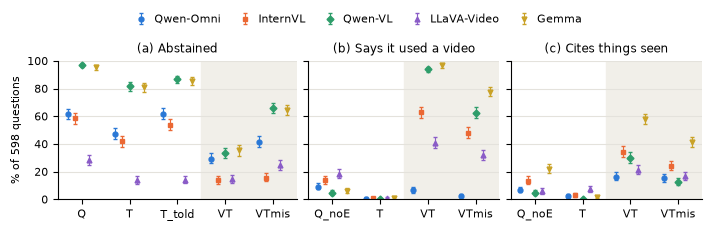

In [4]:
COLORS = dict(zip(data, ["#2a78d6", "#eb6834", "#2e9d6a", "#8a5cc7", "#c9a227", "#d6457a", "#4a4a4a"]))
MARKERS = dict(zip(data, ["o", "s", "D", "^", "v", "P", "X"]))
plt.rcParams.update({"font.size": 8, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "axes.grid.axis": "y", "grid.color": "#e4e2dc", "axes.axisbelow": True, "legend.frameon": False,
                     "pdf.fonttype": 42})


def dodge(ax, column, conditions, title, shade=None):
    for k, (name, df) in enumerate(data.items()):
        x = np.arange(len(conditions)) + (k - (len(data) - 1) / 2) * 0.75 / len(data)
        g = df.groupby("condition")[column]
        value = g.mean().reindex(conditions) * 100
        lo, hi = zip(*[wilson(g.sum()[c], g.size()[c]) for c in conditions])
        ax.errorbar(x, value, yerr=[value - np.array(lo) * 100, np.array(hi) * 100 - value], fmt=MARKERS[name], ms=3.5,
                    color=COLORS[name], capsize=1.5, lw=0.8, label=name)
    if shade is not None:
        ax.axvspan(shade - 0.5, len(conditions) - 0.5, color="#f1efe9", zorder=0)
    ax.set(xticks=range(len(conditions)), xticklabels=conditions, ylim=(0, 100),
           title=title, xlim=(-0.5, len(conditions) - 0.5))
    ax.title.set_size(8.5)


fig, axes = plt.subplots(1, 3, figsize=(7.16, 2.25), gridspec_kw={"width_ratios": [5, 4, 4]})
dodge(axes[0], "abstain", WITH_E, "(a) Abstained", shade=3)
dodge(axes[1], "claims_video", ["Q_noE", "T", "VT", "VTmis"], "(b) Says it used a video", shade=2)
dodge(axes[2], "cites_visual", ["Q_noE", "T", "VT", "VTmis"], "(c) Cites things seen", shade=2)
axes[0].set_ylabel("% of 598 questions")
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=len(data), bbox_to_anchor=(0.5, 1.02),
           handletextpad=0.2, columnspacing=1.2)
fig.tight_layout(rect=(0, 0, 1, 0.9), w_pad=0.6)
fig.savefig(OUT / "fig_conditions.pdf")
plt.show()

## Figure: example question with the right and the wrong clip

qwen-vl-utils using decord to read video.


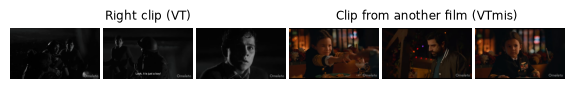

explanation  \
            condition                                                                                                                                                                                                                                                
Qwen-Omni   VT                                                                                                                                            The information is based on the soldier's repeated questioning and the other soldier's continued stance.   
            VTmis                                                                                                                                            The information is based on the lack of any visible or stated emotions from the soldier in the video.   
InternVL    VT                                                                                                                                                         The soldier's facial expression and the urgency in his voice suggest anger and desperation.   
            VTmis                                                                                                                                    The soldier is standing in front of the boy with a determined expression, indicating a mix of fear and anger.   
Qwen-VL     VT                                                                     The soldier's body language and the urgency in his voice suggest he is feeling fearful and angry, as he pleads with the other soldier not to shoot and questions their actions.   
            VTmis      The video does not provide explicit emotional cues or dialogue that directly indicate the soldier's feelings towards the boy or the other soldier, so it is not possible to determine their emotions accurately from the given information.   
LLaVA-Video VT                                                                                                                                      The soldier's expression and body language convey confusion and fear, while the boy looks scared and pleading.   
            VTmis                                                                                         The soldier's expression and body language suggest confusion and fear, as he is standing in front of the boy who is being threatened by another soldier.   
Gemma       VT                                                                    The soldier's facial expression, characterized by wide eyes and a tense, distressed look, conveys a sense of fear and anger as he tries to stop the other soldier from shooting.   
            VTmis                                                                      The provided video clip does not show any soldiers or a scene involving a soldier positioned to shoot, as it depicts a scene from a restaurant involving a child and a man.   

                       cites_visual  notices_mismatch  
            condition                                  
Qwen-Omni   VT                False             False  
            VTmis              True             False  
InternVL    VT                 True             False  
            VTmis              True             False  
Qwen-VL     VT                 True             False  
            VTmis             False             False  
LLaVA-Video VT                 True             False  
            VTmis              True             False  
Gemma       VT                 True             False  
            VTmis              True              True

In [5]:
from common import sample_frames

EXAMPLE = "Y01gr"
questions = pd.read_parquet(ROOT / "data-private/processed/emotion_questions.parquet").set_index("question_id")
mismatch = pd.read_csv(ROOT / "outputs/mismatch_pairs.csv").set_index("question_id")
FRAMES = [10, 32, 54]

fig, axes = plt.subplots(1, 2 * len(FRAMES), figsize=(7.16, 0.95), gridspec_kw={"wspace": 0.03})
for k, (title, clip_id) in enumerate([("Right clip (VT)", EXAMPLE), ("Clip from another film (VTmis)", mismatch.loc[EXAMPLE, "mis_question_id"])]):
    clip = questions.loc[clip_id]
    frames, fps = sample_frames(ROOT / "data-private/raw/all_videos" / f"{clip.movie_title}.mp4", clip.t_i, clip.t_j,
                                int(clip.n_frames), CFG["max_pixels"])
    for j, i in enumerate(FRAMES):
        ax = axes[k * len(FRAMES) + j]
        ax.imshow(frames[i].permute(1, 2, 0).numpy().astype("uint8"))
        ax.set_axis_off()
    axes[k * len(FRAMES) + 1].set_title(title, fontsize=8.5)
fig.savefig(OUT / "fig_example_frames.pdf", bbox_inches="tight", dpi=300)
plt.show()

quotes = pd.concat({name: df[(df.question_id == EXAMPLE) & df.condition.isin(["VT", "VTmis"])].set_index("condition")[["explanation", "cites_visual", "notices_mismatch"]]
                    for name, df in data.items()})
quotes